In [25]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
pd.set_option('display.float_format', lambda x: '%.3f' % x)

In [26]:
df = pd.read_csv("../../data/counters.csv", index_col=0, parse_dates=["datetime"], date_format={"datetime": "ISO8601"})
site_ids = sorted(df.counter_site_id.unique())  # site_ids[i] is "station i" below
print(df.shape)
df.head()

(3360738, 9)


,counter_site_id,counter_serial,channels_in,channels_out,channels_unknown,channels_all,site_temperature,site_rain_accumulation,datetime
0,100003358,YTH24052174,4.000,1.000,NaN,5,0.000,0.000,2020-12-31 23:00:00+00:00
1,100003358,YTH24052174,2.000,0.000,NaN,2,0.000,0.000,2021-01-01 00:00:00+00:00
2,100003358,YTH24052174,1.000,0.000,NaN,1,0.000,0.000,2021-01-01 01:00:00+00:00
3,100003358,YTH24052174,2.000,0.000,NaN,2,0.000,0.000,2021-01-01 02:00:00+00:00
4,100003358,YTH24052174,0.000,0.000,NaN,0,0.000,0.000,2021-01-01 03:00:00+00:00


In [27]:
# What's up with the channels_unknown feature?
mask_unknown = df.channels_unknown.notna()
df.loc[mask_unknown, :].head()

,counter_site_id,counter_serial,channels_in,channels_out,channels_unknown,channels_all,site_temperature,site_rain_accumulation,datetime
147431,100004595,NaN,NaN,NaN,7.000,7,2.000,0.100,2020-12-31 23:00:00+00:00
147432,100004595,NaN,NaN,NaN,2.000,2,2.000,0.200,2021-01-01 00:00:00+00:00
147433,100004595,NaN,NaN,NaN,2.000,2,2.000,0.200,2021-01-01 01:00:00+00:00
147434,100004595,NaN,NaN,NaN,5.000,5,2.000,0.300,2021-01-01 02:00:00+00:00
147435,100004595,NaN,NaN,NaN,6.000,6,2.000,0.300,2021-01-01 03:00:00+00:00


In [28]:
either_mask = (df.channels_unknown.isna() | (df.channels_in.isna() & df.channels_out.isna()))
df.loc[~either_mask, :].head()

,counter_site_id,counter_serial,channels_in,channels_out,channels_unknown,channels_all,site_temperature,site_rain_accumulation,datetime
2297840,100060100,Y2H25043086,20.000,23.000,0.000,43,9.000,0.000,2025-03-27 09:00:00+00:00


In [29]:
(df.channels_in.fillna(0) + df.channels_out.fillna(0) + df.channels_unknown.fillna(0) == df.channels_all).all()#
# It seems like channels_all counts all passengers, in and out count different directions wherever known

np.True_

In [52]:
df.loc[:, ['channels_in', 'channels_out', 'channels_unknown']] = df.loc[:, ['channels_in', 'channels_out', 'channels_unknown']].fillna(0)
# With this interpretation, it makes sense to set all NaNs to zero

In [53]:
df.describe() # Is site_accumulation realistic? The other ones look fine

,counter_site_id,channels_in,channels_out,channels_unknown,channels_all,site_temperature,site_rain_accumulation
count,3360738.000,3360738.000,3360738.000,3360738.000,3360738.000,3294170.000,3294170.000
mean,126228995.138,31.544,30.864,9.760,72.168,11.314,0.098
std,67460514.973,65.830,63.314,68.050,137.516,7.972,0.428
min,100003358.000,0.000,0.000,0.000,0.000,-18.000,0.000
25%,100035363.000,1.000,1.000,0.000,4.000,5.000,0.000
50%,100048814.000,7.000,7.000,0.000,22.000,11.000,0.000
75%,100062943.000,31.000,30.000,0.000,71.000,17.000,0.000
max,300066823.000,7162.000,5804.000,2225.000,9002.000,42.000,30.400


In [61]:
# What about if we aggregate by day?
df.groupby(by=df.datetime.dt.date).max().describe()

,counter_site_id,channels_in,channels_out,channels_unknown,channels_all,site_temperature,site_rain_accumulation
count,2131.000,2131.000,2131.000,2131.000,2131.000,2131.000,2131.000
mean,300066823.000,548.629,517.131,874.821,946.649,17.592,1.909
std,0.000,255.599,245.414,304.388,382.625,8.789,2.868
min,300066823.000,4.000,5.000,7.000,8.000,-2.000,0.000
25%,300066823.000,373.000,377.000,662.500,731.000,11.000,0.100
50%,300066823.000,560.000,529.000,903.000,961.000,17.000,0.900
75%,300066823.000,706.000,646.500,1089.000,1146.000,24.000,2.650
max,300066823.000,7162.000,5804.000,2225.000,9002.000,42.000,30.400


(-20.0, 723.0)

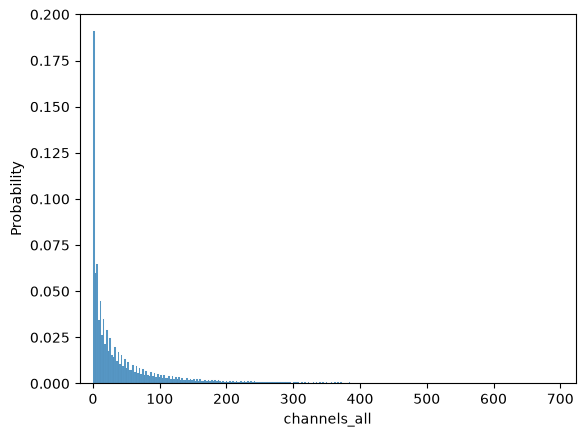

In [ ]:
fig, ax = plt.subplots()
sns.histplot(df.channels_all, ax=ax, stat="probability")
ax.set_xlim(-20, df.channels_all.quantile(0.99))

<Axes: xlabel='site_temperature', ylabel='Count'>

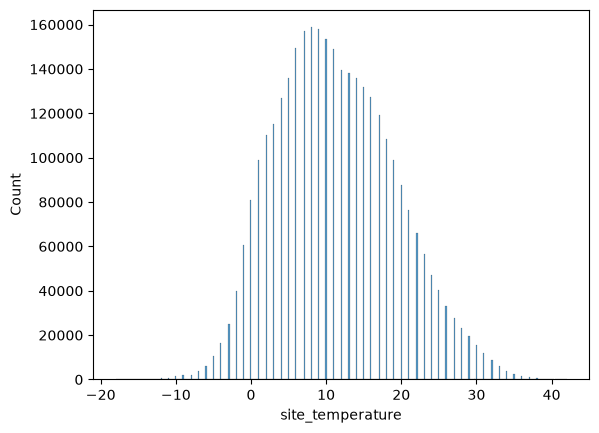

In [9]:
fig, ax = plt.subplots()
sns.histplot(df.site_temperature, ax=ax)

(-20.0, 723.0)

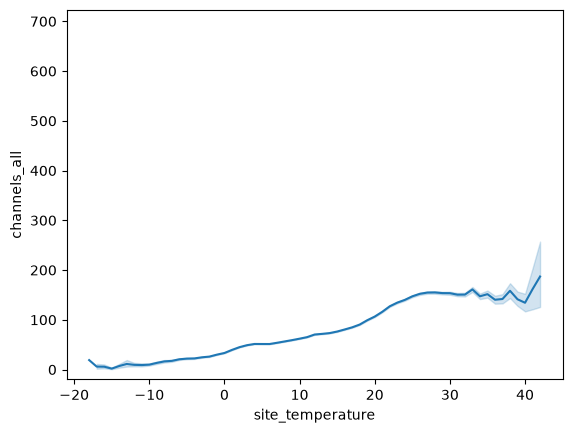

In [10]:
fig, ax = plt.subplots()
sns.lineplot(data=df, x="site_temperature", y="channels_all", ax=ax)
ax.set_ylim(-20, df.channels_all.quantile(0.99))

In [11]:
# It seems like all sites have at least a bit of rain, so maybe they are accurate after all
df.site_rain_accumulation.groupby(by=df.counter_site_id).max().min()


np.float64(12.7)

<Axes: xlabel='datetime', ylabel='channels_all'>

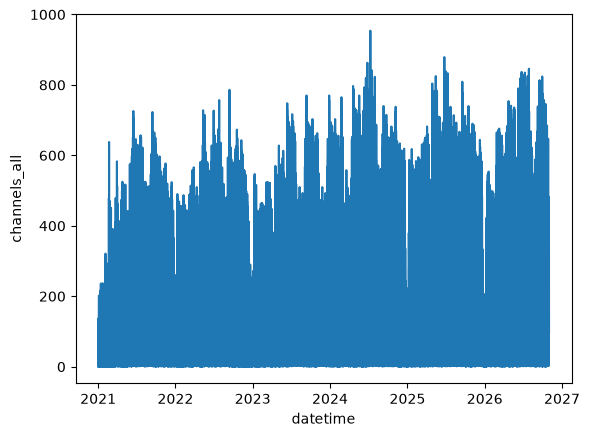

In [12]:
sns.lineplot(data=df.loc[df.counter_site_id == site_ids[0], :], x="datetime", y="channels_all")

/var/folders/32/vygvwqrx4qx5g6w9q4y9ct180000gn/T/ipykernel_40552/3003682384.py:1: Pandas4Warning: Series.dt.weekday is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  sns.catplot(df.groupby(by=df.datetime.dt.weekday).channels_all.mean())


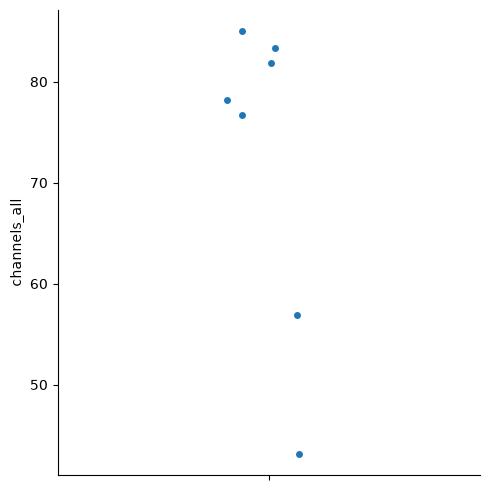

In [13]:
sns.catplot(df.groupby(by=df.datetime.dt.weekday).channels_all.mean())

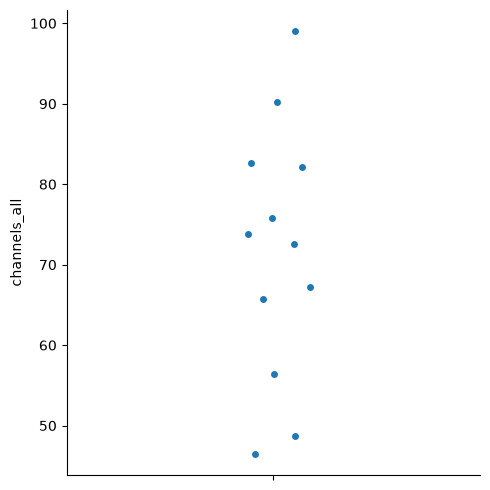

In [14]:
sns.catplot(df.groupby(by=df.datetime.dt.month).channels_all.mean())

In [15]:
station_0 = df.loc[df.counter_site_id == site_ids[0], "channels_all"]
station_0.index = df.loc[df.counter_site_id == site_ids[0], "datetime"]
mean_0 = station_0.mean()
print(mean_0)

print(station_0.size)

188.9364289771058
51061


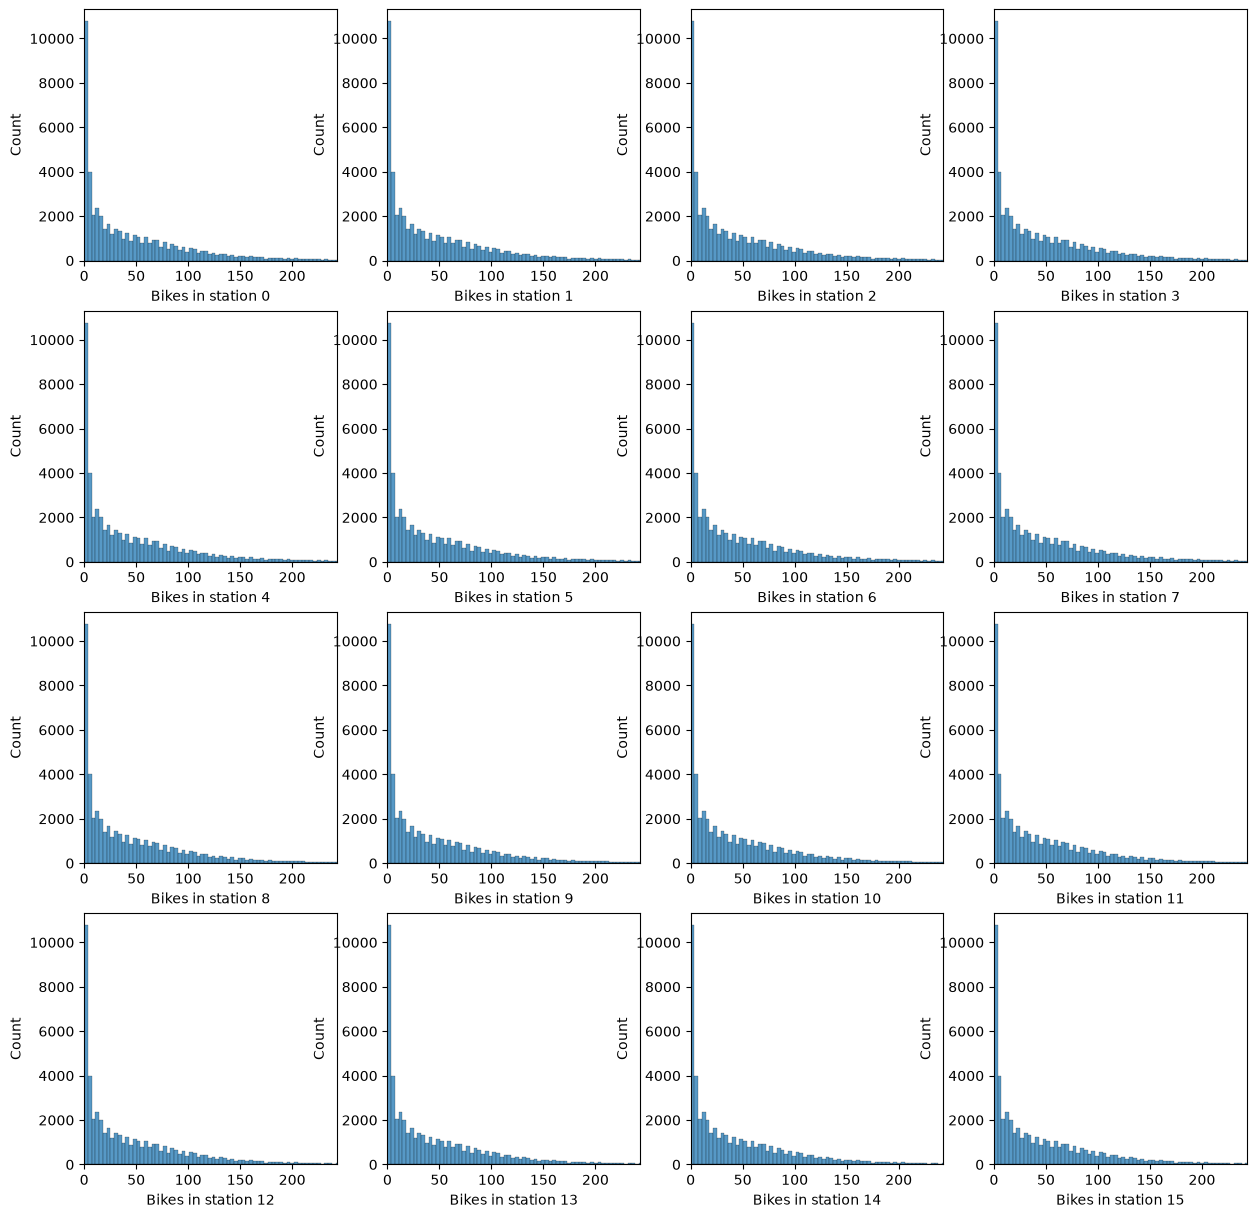

In [23]:
N = 4
fig, axs = plt.subplots(N, N, figsize=(15, 15))
for i in range(N*N):
    ax = axs.flatten()[i]
    station = df.loc[df.counter_site_id == site_ids[i], "channels_all"]
    sns.histplot(station_channel, ax=ax)
    ax.set_xlim(0, station_channel.quantile(0.99))
    ax.set_xlabel(f"Bikes in station {i}")

(0.0, 1.7)

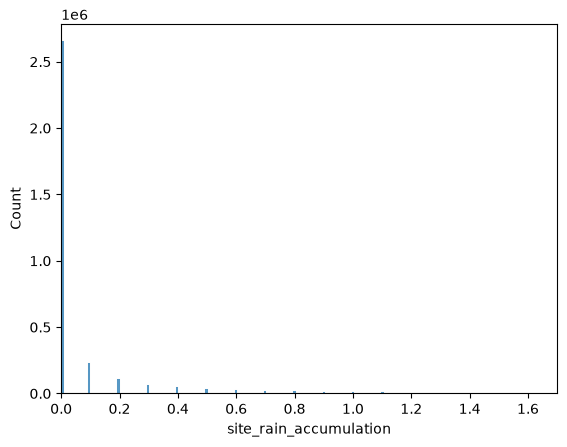

In [17]:
nonzero_rain_mask = df.site_rain_accumulation > 0

fig, ax = plt.subplots()
sns.histplot(df.site_rain_accumulation, ax=ax)
ax.set_xlim(0, df.site_rain_accumulation.quantile(0.99))

(-20.0, 723.0)

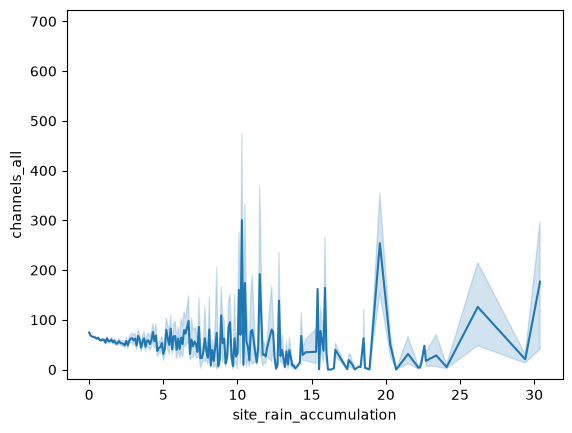

In [18]:
fig, ax = plt.subplots()
sns.lineplot(data=df, x="site_rain_accumulation", y="channels_all", ax=ax)
ax.set_ylim(-20, df.channels_all.quantile(0.99))

(-20.0, 723.0)

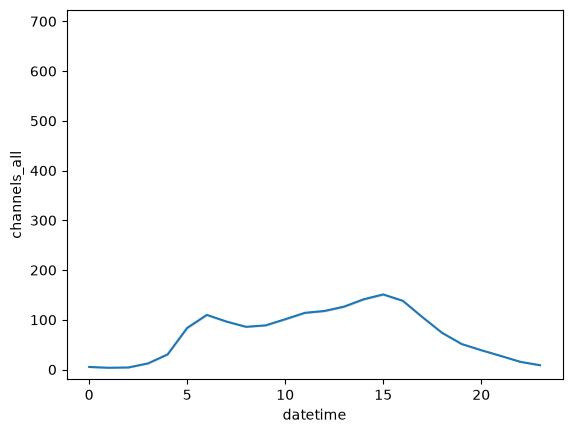

In [19]:
fig, ax = plt.subplots()
sns.lineplot(data=df, x=df.datetime.dt.hour, y="channels_all", ax=ax)
ax.set_ylim(-20, df.channels_all.quantile(0.99))

In [20]:
df.groupby(by="counter_site_id").channels_all.count().describe()

count      68.000
mean    49422.618
std      3736.408
min     27348.000
25%     49606.750
50%     51071.000
75%     51114.000
max     51114.000
Name: channels_all, dtype: float64

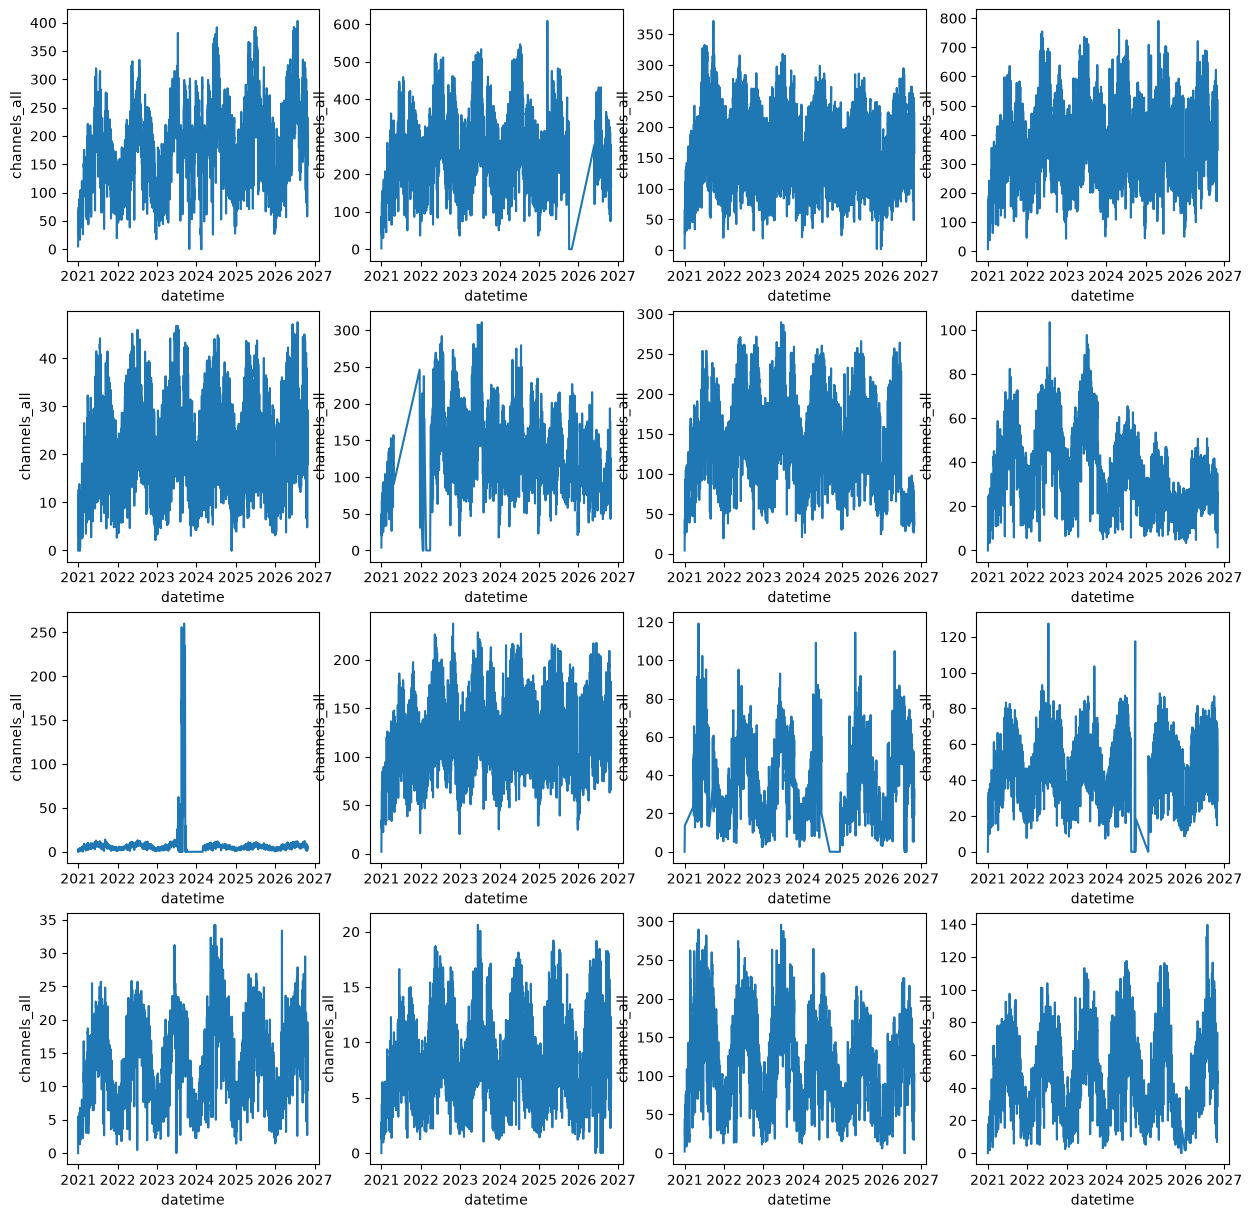

In [67]:
N = 4
fig, axs = plt.subplots(N, N, figsize=(15, 15))
for i in range(N*N):
    ax = axs.flatten()[i]
    station = df.loc[df.counter_site_id == site_ids[i], :]
    day_means = station.channels_all.groupby(by=station.datetime.dt.date).mean()
    sns.lineplot(data=day_means, ax=ax)

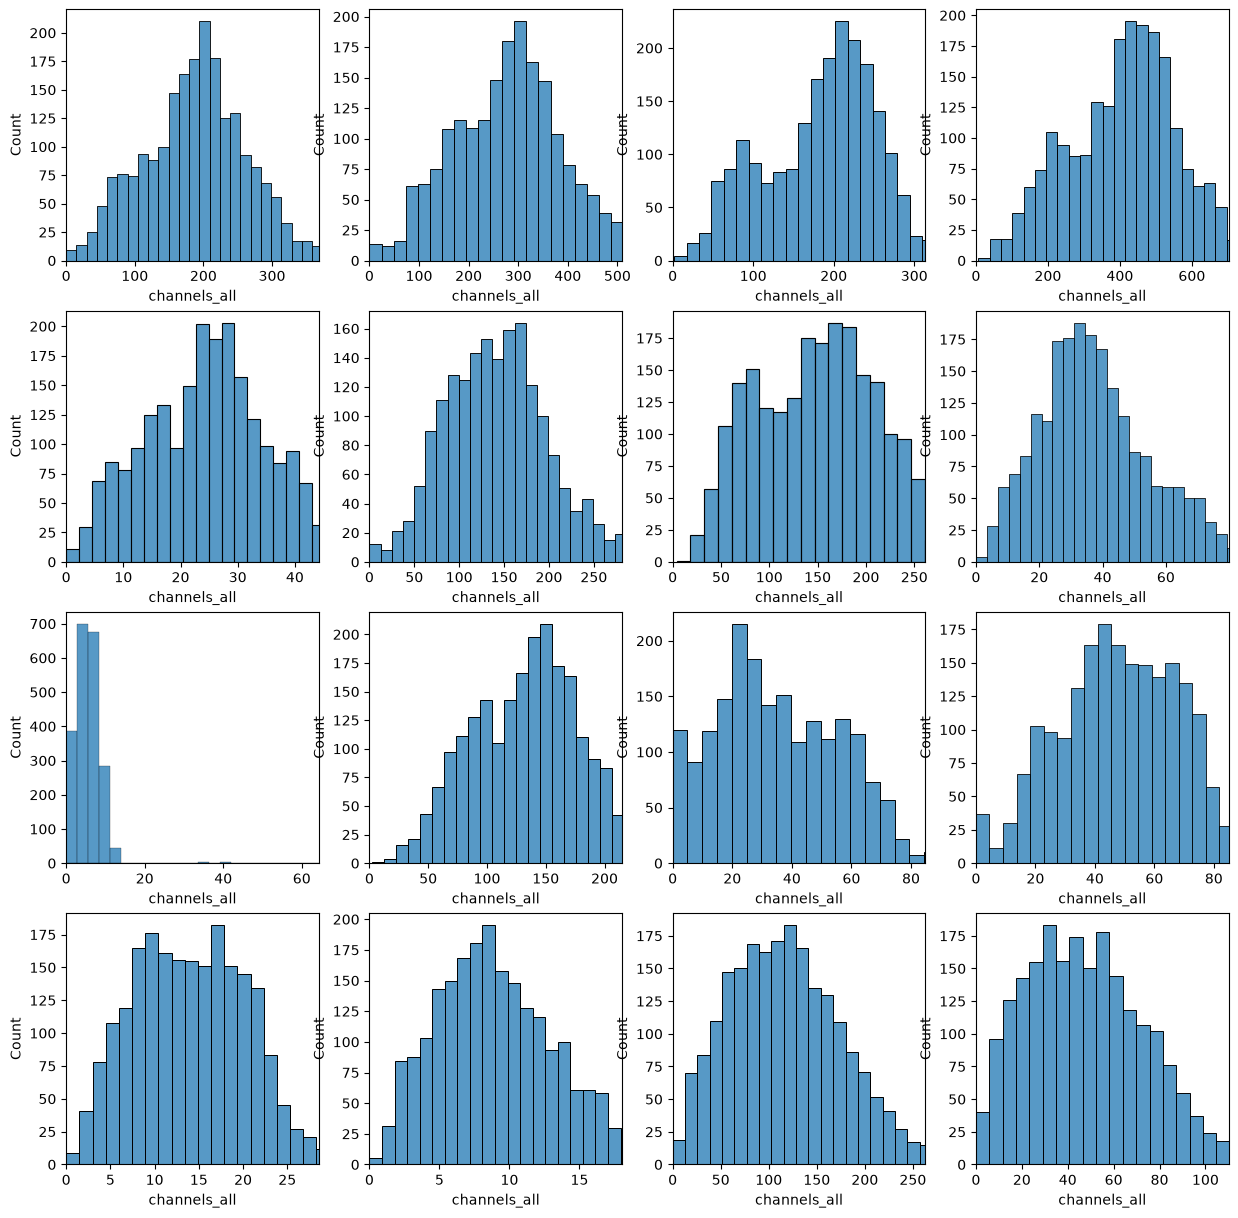

In [ ]:
N = 4
fig, axs = plt.subplots(N, N, figsize=(15, 15))
for i in range(N*N):
    ax = axs.flatten()[i]
    station = df.loc[df.counter_site_id == site_ids[i], :]
    day_means = station.channels_all.groupby(by=station.datetime.dt.date).mean()
    sns.histplot(day_peaks, ax=ax)
    ax.set_xlim((0, day_peaks.quantile(0.99)))